# ChurnIQ — Customer Retention Intelligence

## Project Overview
ChurnIQ is a Machine Learning project that predicts whether a telecom customer is likely to leave a company.

## Objective
- Understand and analyze customer data.
- Identify factors associated with customer churn.
- Train and evaluate Machine Learning models.
- Build a reliable prediction pipeline.
- Deploy the final model as a web application.

## Dataset
IBM Telco Customer Churn Dataset

## Target Variable
Churn

In [1]:
# Importing the libraries
# Rest Libraries will be imported on use
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the IBM Telco Customer Churn dataset into a Pandas DataFrame
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df= pd.read_csv(url)

In [3]:
# Display the first five rows of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Info of the datset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
# Shape of the dataset
df.shape

(7043, 21)

In [6]:
# Stasstical values of each numerical columnn
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# Check the number of missing values in each column
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
# Check for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [9]:
# Count the number of customers in each churn category
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [10]:
# Calculate the percentage distribution of churn classes
df["Churn"].value_counts(normalize=True).mul(100).round(2)

,proportion
Churn,
No,73.46
Yes,26.54


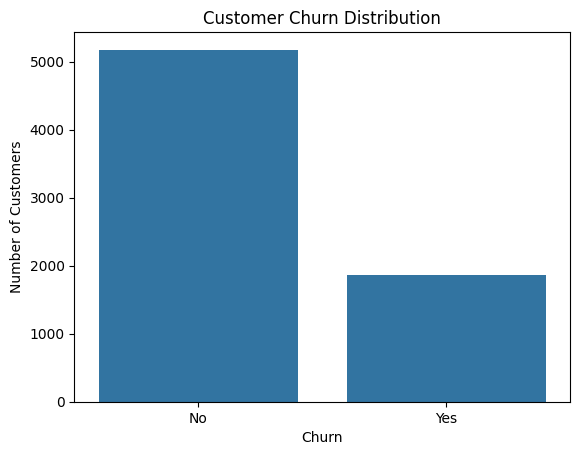

In [11]:
# Visualize the distribution of customers across churn categories
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [12]:
# Identify numerical and categorical columns in the dataset

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [13]:
# Inspect the data type and sample values of TotalCharges

print("Data type:", df["TotalCharges"].dtype)
print("\nSample values:")
print(df["TotalCharges"].head(10).tolist())

print("\nBlank or whitespace-only values:",
      df["TotalCharges"].astype(str).str.strip().eq("").sum())

Data type: object

Sample values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']

Blank or whitespace-only values: 11


In [14]:
# Identify rows where TotalCharges contains blank or whitespace values

blank_mask = df["TotalCharges"].astype(str).str.strip().eq("")
display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [15]:
# Convert blank TotalCharges values to NaN and cast the column to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip().replace("", np.nan),
    errors="coerce"
)
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

Data type: float64
Missing values: 11


In [16]:
# Recheck missing values after converting TotalCharges to numeric

df.isnull().sum()[df.isnull().sum() > 0]

,0
TotalCharges,11


In [17]:
# Calculate the percentage of missing values in each affected column

missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage[missing_percentage > 0].round(3)

,0
TotalCharges,0.156


In [18]:
# Create a working copy and handle missing TotalCharges for zero-tenure customers

df_clean = df.copy()
zero_tenure_missing = (
    (df_clean["tenure"] == 0) &
    (df_clean["TotalCharges"].isnull())
)
df_clean.loc[zero_tenure_missing, "TotalCharges"] = 0

print("Remaining missing values:", df_clean["TotalCharges"].isnull().sum())
print("Rows preserved:", len(df_clean))

Remaining missing values: 0
Rows preserved: 7043


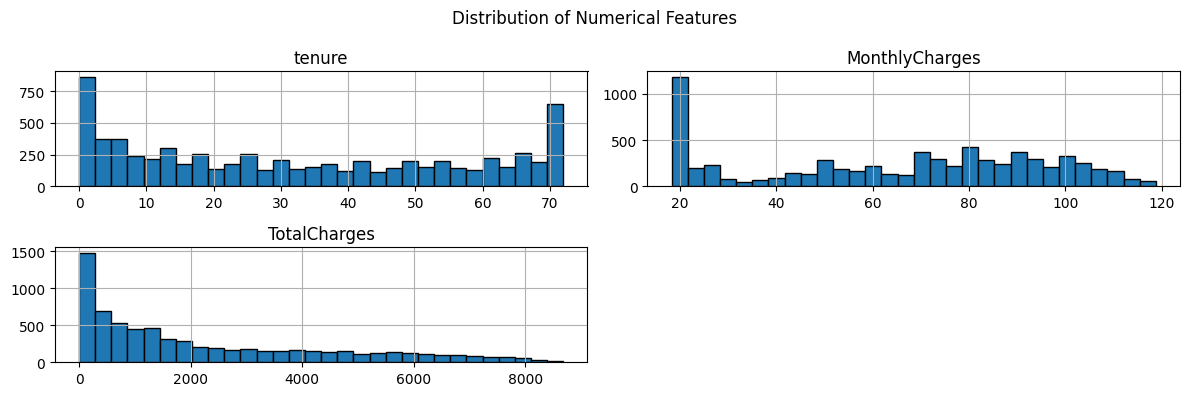

In [19]:
# Visualize the distributions of numerical features

df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].hist(
    figsize=(12, 4),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [20]:
# Analyze the distribution of customer contract types

df_clean["Contract"].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


In [21]:
# Analyze churn distribution across different contract types
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


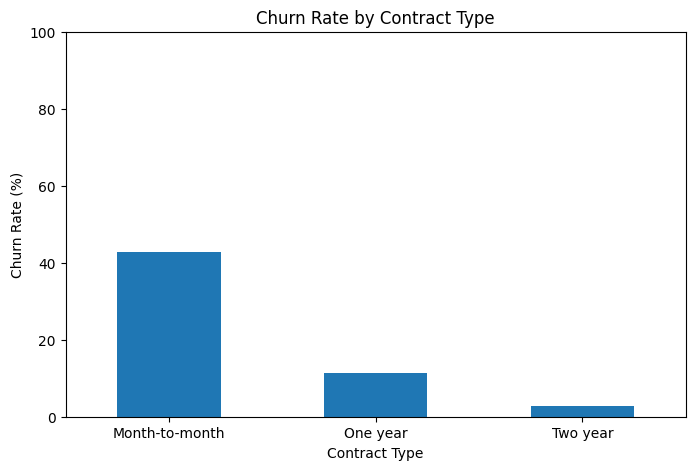

In [22]:
# Visualize churn rate across different contract types

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn["Yes"].plot(kind="bar", figsize=(8, 5))

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

In [23]:
# Compare customer tenure across churn categories

df_clean.groupby("Churn")["tenure"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


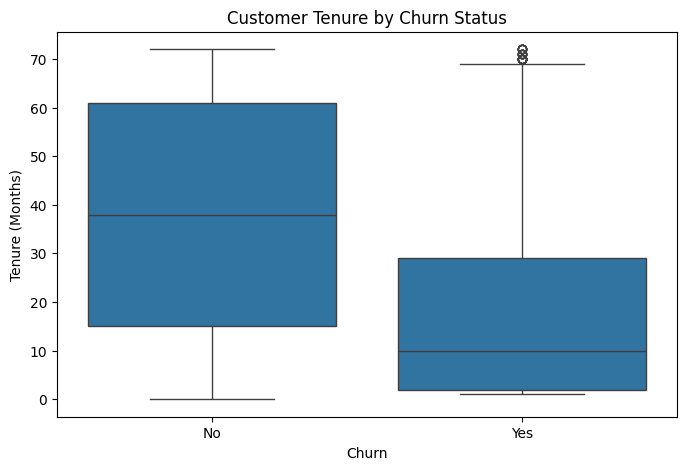

In [24]:
# Compare tenure distributions for churned and retained customers

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

In [25]:
# Compare average monthly charges for churned and retained customers

df_clean.groupby("Churn")["MonthlyCharges"].mean().round(2)

,MonthlyCharges
Churn,
No,61.27
Yes,74.44


In [26]:
# Compare churn rates across different payment methods

pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [27]:
# Compare churn rates across internet service types

pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [28]:
# Compare churn rates across all categorical features

categorical_cols = df_clean.select_dtypes(include="object").columns.drop(
    ["customerID", "Churn", "TotalCharges"],
    errors="ignore"
)

for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(
        pd.crosstab(
            df_clean[col],
            df_clean["Churn"],
            normalize="index"
        ).mul(100).round(2)
    )


--- gender ---


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16



--- Partner ---


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66



--- Dependents ---


...

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



--- PaperlessBilling ---


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57



--- PaymentMethod ---


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


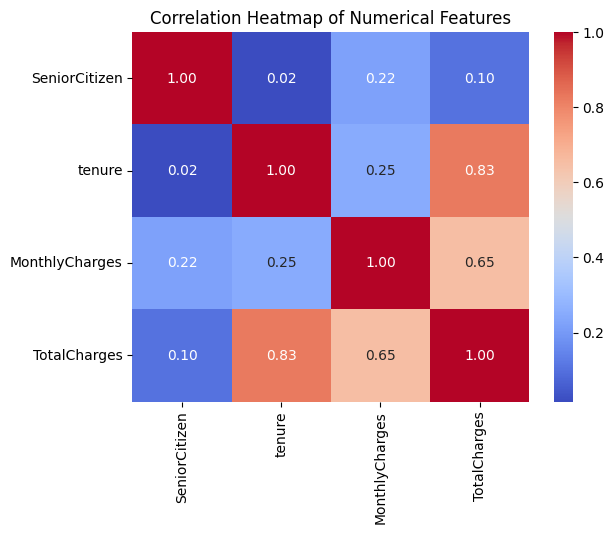

In [29]:
# Analyze correlations among numerical features

numerical_df = df_clean[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [30]:
# Compare numerical features by churn status

df_clean.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


In [31]:
# Check target distribution in percentage

df_clean["Churn"].value_counts(normalize=True).mul(100).round(2)

,proportion
Churn,
No,73.46
Yes,26.54


In [32]:
# Separate input features and target

X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


,Churn
0,0
1,0
2,1
3,0
4,1


In [33]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)
print("Training churn proportion:\n",y_train.value_counts(normalize=True).round(2))
print("Testing churn proportion:\n", y_test.value_counts(normalize=True).round(2))

Training set shape: (5634, 19) (5634,)
Testing set shape: (1409, 19) (1409,)
Training churn proportion:
 Churn
0    0.73
1    0.27
Name: proportion, dtype: float64
Testing churn proportion:
 Churn
0    0.73
1    0.27
Name: proportion, dtype: float64


In [34]:
# Identify categorical and numerical columns from training data

categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical features:", len(numerical_cols))
print(numerical_cols)

Categorical features: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features: 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical features: scale values
# Categorical features: one-hot encode categories

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and model into one workflow
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [37]:
# Train the complete pipeline
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [38]:
# Predict churn for unseen test customers

y_pred = model.predict(X_test)

In [39]:
from sklearn.metrics import confusion_matrix, classification_report

# Compare predictions with actual labels
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

Confusion Matrix:
[[926 109]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [40]:
# Get churn probabilities for test customers

y_prob = model.predict_proba(X_test)[:, 1]

print("First 10 churn probabilities:")
print(y_prob[:10].round(3))

First 10 churn probabilities:
[0.046 0.684 0.059 0.402 0.021 0.603 0.448 0.13  0.003 0.395]


In [41]:
from sklearn.metrics import classification_report, confusion_matrix

# Apply a lower churn probability threshold
y_pred_035 = (y_prob >= 0.35).astype(int)

print("Confusion Matrix (Threshold = 0.35):")
print(confusion_matrix(y_test, y_pred_035))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_035,
    target_names=["No Churn", "Churn"]
))

Confusion Matrix (Threshold = 0.35):
[[813 222]
 [110 264]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [42]:
# Explore customer tenure groups before feature engineering

tenure_groups = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

print(tenure_groups.value_counts().sort_index())

tenure
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


In [43]:
# Compare churn rate across tenure groups

tenure_analysis = pd.DataFrame({
    "TenureGroup": tenure_groups,
    "Churn": df_clean["Churn"]
})

churn_by_tenure = (
    tenure_analysis.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .round(2)
)

print("Churn rate by tenure group (%):")
print(churn_by_tenure)

Churn rate by tenure group (%):
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


In [44]:
# Add tenure groups to train and test features

tenure_bins = [-1, 12, 24, 48, 72]
tenure_labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

X_train_fe["TenureGroup"] = pd.cut(
    X_train_fe["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

X_test_fe["TenureGroup"] = pd.cut(
    X_test_fe["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

print("Training features:", X_train_fe.shape)
print("Testing features:", X_test_fe.shape)

Training features: (5634, 20)
Testing features: (1409, 20)


In [45]:
# Update feature column lists

categorical_cols_fe = X_train_fe.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols_fe = X_train_fe.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Categorical features:", len(categorical_cols_fe))
print("Numerical features:", len(numerical_cols_fe))

Categorical features: 16
Numerical features: 4


In [47]:
# preprocessor with tenure group
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols_fe),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols_fe)
    ]
)

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model_fe = Pipeline([
    ("preprocessing", preprocessor_fe),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using the new feature
model_fe.fit(X_train_fe, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'TenureGroup'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Generate predictions on the same test customers
y_pred_base = model.predict(X_test)
y_pred_fe = model_fe.predict(X_test_fe)

# Compare model performance
results = pd.DataFrame({
    "Baseline": [
        accuracy_score(y_test, y_pred_base),
        precision_score(y_test, y_pred_base),
        recall_score(y_test, y_pred_base),
        f1_score(y_test, y_pred_base)
    ],
    "With TenureGroup": [
        accuracy_score(y_test, y_pred_fe),
        precision_score(y_test, y_pred_fe),
        recall_score(y_test, y_pred_fe),
        f1_score(y_test, y_pred_fe)
    ]
}, index=["Accuracy", "Churn Precision", "Churn Recall", "Churn F1-score"])

display(results.round(3))

,Baseline,With TenureGroup
Accuracy,0.806,0.799
Churn Precision,0.657,0.653
Churn Recall,0.559,0.519
Churn F1-score,0.604,0.578


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

In [51]:
# Train the Random Forest pipeline
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on the same test set
y_pred_rf = rf_model.predict(X_test)

# Compare against the baseline Logistic Regression
comparison = pd.DataFrame({
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_base),
        precision_score(y_test, y_pred_base),
        recall_score(y_test, y_pred_base),
        f1_score(y_test, y_pred_base)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ]
}, index=["Accuracy", "Churn Precision", "Churn Recall", "Churn F1-score"])

display(comparison.round(3))

,Logistic Regression,Random Forest
Accuracy,0.806,0.783
Churn Precision,0.657,0.619
Churn Recall,0.559,0.473
Churn F1-score,0.604,0.536


In [53]:
# Get churn probabilities from Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 Random Forest churn probabilities:")
print(y_prob_rf[:10].round(3))

First 10 Random Forest churn probabilities:
[0.    0.705 0.075 0.29  0.005 0.385 0.405 0.115 0.    0.435]


In [54]:
from sklearn.metrics import classification_report, confusion_matrix

# Apply threshold = 0.35
y_pred_rf_035 = (y_prob_rf >= 0.35).astype(int)

print("Confusion Matrix (Threshold = 0.35):")
print(confusion_matrix(y_test, y_pred_rf_035))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_035,
    target_names=["No Churn", "Churn"]
))

Confusion Matrix (Threshold = 0.35):
[[837 198]
 [127 247]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.81      0.84      1035
       Churn       0.56      0.66      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.79      0.77      0.78      1409



In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Logistic Regression
y_prob_lr = model.predict_proba(X_test)[:, 1]

# Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_lr), 4))

print("\nRandom Forest")
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_rf), 4))

Logistic Regression
ROC-AUC: 0.8421
PR-AUC: 0.6343

Random Forest
ROC-AUC: 0.8232
PR-AUC: 0.6145


In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": (model, X_test),
    "Random Forest": (rf_model, X_test)
}

results = []

for name, (clf, X_eval) in models.items():
    pred = clf.predict(X_eval)
    prob = clf.predict_proba(X_eval)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Churn Precision": round(precision_score(y_test, pred), 4),
        "Churn Recall": round(recall_score(y_test, pred), 4),
        "Churn F1": round(f1_score(y_test, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4)
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232


In [57]:
# Train a Decision Tree model
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ))
])

# Train and predict
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

In [58]:
# Evaluate Decision Tree model
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test, y_pred_dt,
    target_names=["No Churn", "Churn"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_dt), 4))

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8284


In [59]:
# Train a Gradient Boosting model
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

In [60]:
# Evaluate Gradient Boosting model
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test, y_pred_gb,
    target_names=["No Churn", "Churn"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb), 4))

              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8434


In [61]:
# Train an SVM model
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

In [62]:
# Evaluate SVM model
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test, y_pred_svm,
    target_names=["No Churn", "Churn"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_svm), 4))

              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.77      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC: 0.821


In [63]:
# Compare all trained models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

trained_models = {
    "Logistic Regression": (model, X_test),
    "Random Forest": (rf_model, X_test),
    "Decision Tree": (dt_model, X_test),
    "Gradient Boosting": (gb_model, X_test),
    "SVM": (svm_model, X_test)
}

comparison = []

for name, (clf, X_eval) in trained_models.items():
    pred = clf.predict(X_eval)
    prob = clf.predict_proba(X_eval)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Churn Precision": round(precision_score(y_test, pred), 4),
        "Churn Recall": round(recall_score(y_test, pred), 4),
        "Churn F1": round(f1_score(y_test, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.sort_values("ROC-AUC", ascending=False)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8434
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
2,Decision Tree,0.7402,0.5069,0.7888,0.6172,0.8284
1,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
4,SVM,0.7438,0.5115,0.7727,0.6155,0.8210


In [65]:
# Save the selected Logistic Regression model
# beacuase it best accuracy then others
import joblib

joblib.dump(model, "churniq_model.pkl")

['churniq_model.pkl']